In [ ]:
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, "..")  # repo root, so `core` is importable from notebooks/

from core.offline import collect_offline_trajectories
from core.radius import estimate_radius, fit_predictor
from core.drmpc import make_controller, simulate, closed_loop_metrics
from core.generate_rng import trial_rngs

## Mass-spring-damper, set up like the paper's numerical experiment

m = 1 kg, k = 1 N/m, c = 1 N·s/m, Euler with dt = 0.1 s. State [position, velocity], input = force. Like the paper's system, the force enters the velocity and reaches the position one step later, and A is stable (max |eigenvalue| 0.954; the paper's is 0.97).

| | Paper | Mass-spring-damper |
|---|---|---|
| Cost | pull x₁ toward 2 | pull the position toward 2 m |
| Bound | x₁ ≤ 1, x₂ ≥ 0 | a hard stop at position ≤ 1 m (no velocity bound) |
| Start | [0.9, 0.9] | [0.9, 0]: 10 cm from the stop, at rest |
| Horizon, noise, N, trials, steps | T=5, 0.03, 10–40, 50, 30 | same |
| Offline force std | 0.5 (B = [0, 1]) | 5 (B = [0, 0.1]), so the input-to-noise ratio matches |

In [ ]:
mass, k, c, dt = 1.0, 1.0, 1.0, 0.1
A = np.eye(2) + dt * np.array([[0, 1], [-k / mass, -c / mass]])
B = dt * np.array([[0.0], [1 / mass]])
n, m, T = 2, 1, 5
X0 = [0.9, 0.0]
ACTION_STD = 5.0
SEED = 0  # trial k draws from trial_rngs(SEED, k)
spec = dict(state_weight=[1, 0], ref=[2, 0], x_min=[-np.inf, -np.inf], x_max=[1, np.inf])
print("A =", A.tolist(), "| max |eig| =", np.abs(np.linalg.eigvals(A)).max().round(4))

## Collect offline trajectories and estimate the radius of uncertainty

In [ ]:
rng_data, rng_noise = trial_rngs(SEED, 0)
Z, Y = collect_offline_trajectories(A, B, 10, T, action_std=ACTION_STD, rng=rng_data)
L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
W = rng_noise.normal(0, 0.03, (30, n))

def run(L_hat, Z, Y, eps1, eps2, W, return_states=False):
    """Closed-loop (cost, violations) from X0; (nan, nan) if the run fails."""
    try:
        controller = make_controller(L_hat, Z, Y, n, m, eps1, eps2, **spec)
        X, _ = simulate(A, B, controller, X0, W)
        return X if return_states else closed_loop_metrics(X, **spec)
    except RuntimeError:
        return None if return_states else (np.nan, np.nan)

eps1 = 0.00031, eps2 = 0.02
SAAMPC failed


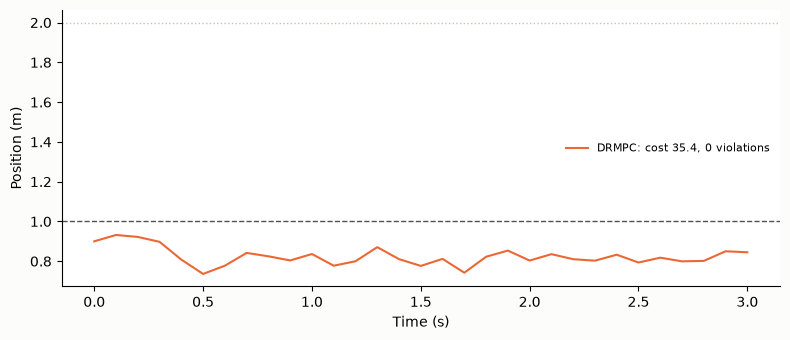

In [4]:
COLORS = {"SAAMPC": "#2a78d6", "DRMPC": "#eb6834"}
print(f"eps1 = {eps1:.2g}, eps2 = {eps2:.2g}")
fig, ax = plt.subplots(figsize=(8, 3.5), facecolor="#fcfcfb")
for name, (e1, e2) in {"SAAMPC": (0.0, 0.0), "DRMPC": (eps1, eps2)}.items():
    X = run(L_hat, Z, Y, e1, e2, W, return_states=True)
    if X is None:
        print(f"{name} failed")
        continue
    cost, violations = closed_loop_metrics(X, **spec)
    ax.plot(np.arange(len(X)) * dt, X[:, 0], color=COLORS[name], label=f"{name}: cost {cost:.1f}, {violations} violations")
ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
ax.axhline(2, color="#c3c2b7", linestyle=":", linewidth=1)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Position (m)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Animation of the same run

Saved to `notebooks/mass_spring_damper.gif`, played at half speed. The black arrow is the applied force (0.15 m per N, capped at 1 m; the label gives the exact value). If a controller's solver gives up, the video holds its last state and says so.

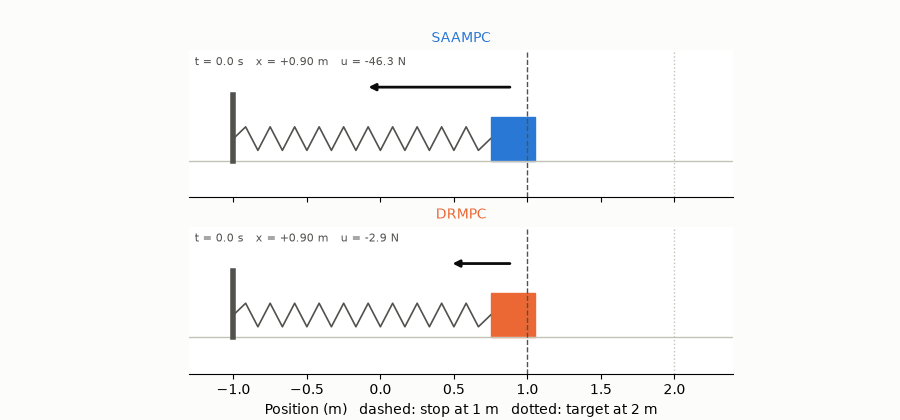

In [5]:
from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter


def rollout(e1, e2):
    """States and forces until W runs out or the solver gives up (simulate would discard them)."""
    controller = make_controller(L_hat, Z, Y, n, m, e1, e2, **spec)
    X, U = [np.array(X0, float)], []
    for w in W:
        try:
            u = controller(X[-1])[:m]
        except RuntimeError:
            break
        U.append(u[0])
        X.append(A @ X[-1] + B @ u + w)
    return np.array(X), np.array(U)


rolls = {"SAAMPC": rollout(0.0, 0.0), "DRMPC": rollout(eps1, eps2)}
VIEW, ANCHOR = (-1.3, 2.4), -1.0
ARROW_PER_N, ARROW_MAX = 0.15, 1.0  # arrow length in m per N, capped; the label has the exact force
fig, axes = plt.subplots(2, 1, figsize=(9, 4.2), sharex=True, facecolor="#fcfcfb")
parts = []
for ax, (name, (X, U)) in zip(axes, rolls.items()):
    ax.set_xlim(*VIEW)
    ax.set_ylim(-0.45, 0.55)
    ax.set_aspect("equal")
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.set_title(name, color=COLORS[name], fontsize=10)
    ax.axhline(-0.2, color="#c3c2b7", linewidth=1)
    ax.plot([ANCHOR, ANCHOR], [-0.2, 0.25], color="#52514e", linewidth=4)
    ax.axvline(1, color="#52514e", linestyle="--", linewidth=1)
    ax.axvline(2, color="#c3c2b7", linestyle=":", linewidth=1)
    mass = plt.Rectangle((0, -0.2), 0.3, 0.3, color=COLORS[name])
    ax.add_patch(mass)
    (spring,) = ax.plot([], [], color="#52514e", linewidth=1.2)
    label = ax.text(0.01, 0.9, "", transform=ax.transAxes, fontsize=8, color="#52514e")
    arrow = ax.annotate("", xy=(0, 0.3), xytext=(0, 0.3),
                        arrowprops=dict(arrowstyle="-|>", color="#0b0b0b", linewidth=2))
    parts.append((X, U, mass, spring, label, arrow))
axes[-1].set_xlabel("Position (m)   dashed: stop at 1 m   dotted: target at 2 m")


def draw(k):
    for X, U, mass, spring, label, arrow in parts:
        j = min(k, len(X) - 1)
        x = X[j, 0]
        u = U[j] if j < len(U) else 0.0  # force applied from this state to the next
        arrow.xy = (x + np.clip(ARROW_PER_N * u, -ARROW_MAX, ARROW_MAX), 0.3)
        arrow.set_position((x, 0.3))
        arrow.set_visible(j < len(U) and abs(u) > 1e-3)
        mass.set_x(x - 0.15)
        coils = np.linspace(ANCHOR, x - 0.15, 22)
        spring.set_data(coils, np.r_[0, 0.08 * (-1) ** np.arange(20), 0] - 0.05)
        text = f"t = {j * dt:.1f} s   x = {x:+.2f} m   u = {u:+.1f} N"
        if not VIEW[0] < x < VIEW[1]:
            text += "   (off screen)"
        if len(X) <= len(W) and k >= len(X) - 1:
            text += f"   solver failed after step {len(X) - 1}"
        label.set_text(text)
    return [a for _, _, *rest in parts for a in rest]


animation = FuncAnimation(fig, draw, frames=len(W) + 1)
animation.save("mass_spring_damper.gif", writer=PillowWriter(fps=5))  # 5 fps = half speed (dt = 0.1 s)
plt.close(fig)
Image(filename="mass_spring_damper.gif")

## Fig. 1: effect of the radius

As in the paper: one dataset of size N=10 and one noise realization, every combination of eps1 and eps2 in {1e-7, ..., 1}, with the least-squares predictor. Seed 0, not selected.

/Users/awolf/Code/optimization/DRMPC-Robotics-Finance/drmpc/../core/drmpc.py:74: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(solver=cp.CLARABEL, canon_backend=cp.SCIPY_CANON_BACKEND)


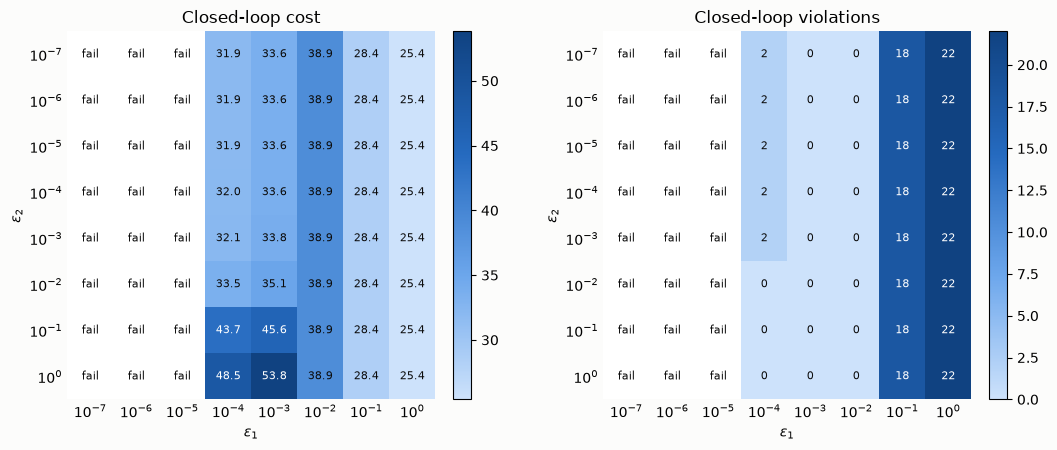

In [6]:
EPS_GRID = 10.0 ** np.arange(-7, 1)

# Separate RNG, so the Fig. 2 sweep below is unaffected.
fig1_rng = np.random.default_rng(0)
Z, Y = collect_offline_trajectories(A, B, 10, T, action_std=ACTION_STD, rng=fig1_rng)
W = fig1_rng.normal(0, 0.03, (30, n))

L_fit = fit_predictor(Z, Y, n, m)  # eq. 13; Fig. 1 uses least squares, not Algorithm 1
grid = np.array([[run(L_fit, Z, Y, e1, e2, W) for e1 in EPS_GRID] for e2 in EPS_GRID])
cost_grid, violation_grid = grid[..., 0], grid[..., 1]

BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#104281"])
labels = [f"$10^{{{e}}}$" for e in range(-7, 1)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), facecolor="#fcfcfb")
for ax, values, title, fmt in [
    (axes[0], cost_grid, "Closed-loop cost", "{:.1f}"),
    (axes[1], violation_grid, "Closed-loop violations", "{:.0f}"),
]:
    image = ax.imshow(values, cmap=BLUES)
    midpoint = np.nanmean([np.nanmin(values), np.nanmax(values)])
    for (i, j), value in np.ndenumerate(values):
        text = "fail" if np.isnan(value) else fmt.format(value)
        ax.text(j, i, text, ha="center", va="center", fontsize=8,
                color="#ffffff" if value > midpoint else "#0b0b0b")
    ax.set_xticks(range(8), labels)
    ax.set_yticks(range(8), labels)
    ax.set_xlabel("$\\varepsilon_1$")
    ax.set_ylabel("$\\varepsilon_2$")
    ax.set_title(title)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

## Fig. 2: SAAMPC vs. DRMPC by dataset size

For N = 10, 20, 30 and 40, we repeat 50 times with a new dataset and noise realization. Trial k draws its data and noise from `trial_rngs(SEED, k)`, so any other controller (e.g. DeePC) can be run against the same noise. DRMPC uses the Algorithm 1 radius and SAAMPC sets the radius to 0, with the same predictor, data and noise. A run counts as failed if the solver gives up, which usually means the closed loop diverged.

In [ ]:
results = {}
for num_trajectories in [10, 20, 30, 40]:
    runs = {"SAAMPC": [], "DRMPC": []}

    for trial in range(50):
        rng_data, rng_noise = trial_rngs(SEED, trial)
        Z, Y = collect_offline_trajectories(A, B, num_trajectories, T, action_std=ACTION_STD, rng=rng_data)
        L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
        W = rng_noise.normal(0, 0.03, (30, n))
        runs["SAAMPC"].append(run(L_hat, Z, Y, 0.0, 0.0, W))
        runs["DRMPC"].append(run(L_hat, Z, Y, eps1, eps2, W))

    results[num_trajectories] = {name: np.array(r) for name, r in runs.items()}
    for name, r in results[num_trajectories].items():
        costs, violations = r.T
        print(
            f"N={num_trajectories} {name:<6}: failed {np.isnan(costs).sum()}/50 | "
            f"cost mean {np.nanmean(costs):.2f}, median {np.nanmedian(costs):.2f}, "
            f"range {np.nanmin(costs):.1f}-{np.nanmax(costs):.1f} | "
            f"violations mean {np.nanmean(violations):.2f}, median {np.nanmedian(violations):.1f}, "
            f"zero in {(violations == 0).sum()}/50"
        )

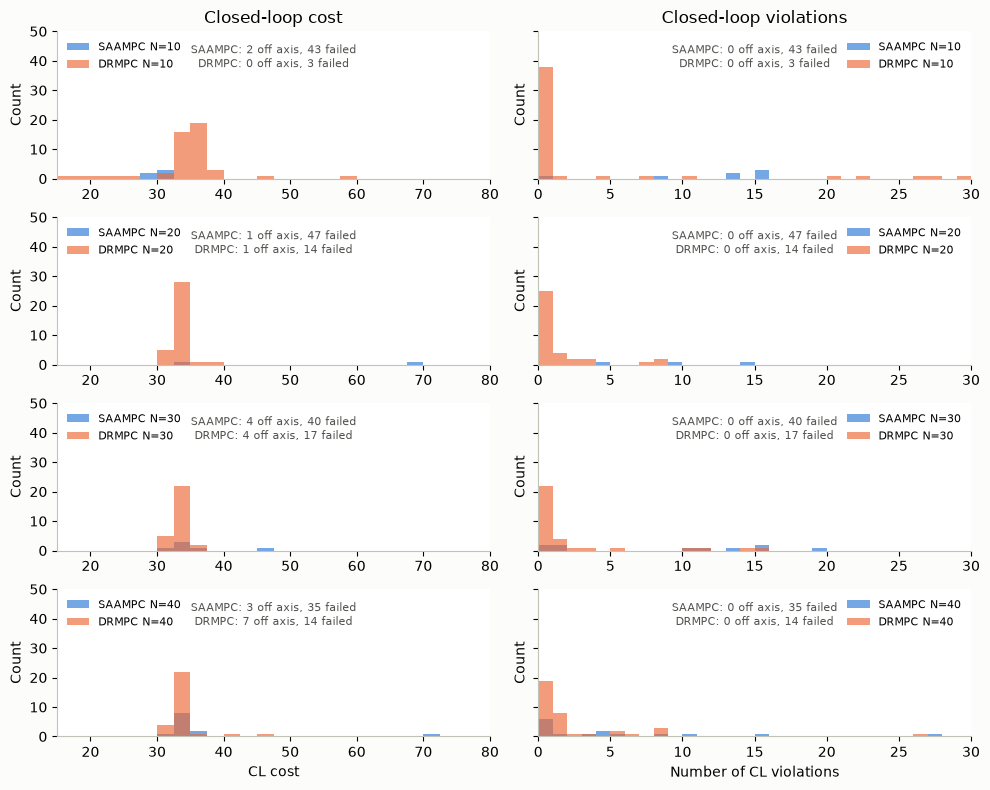

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(10, 8), sharey=True, facecolor="#fcfcfb")
# Non-diverged runs cost about 15-80; diverged ones reach 1e6 and are counted as off axis.
cost_bins = np.linspace(15, 80, 27)
panels = [(0, cost_bins, "CL cost"), (1, np.arange(0, 31), "Number of CL violations")]

for row, (num_trajectories, by_name) in zip(axes, results.items()):
    for ax, (column, bins, xlabel) in zip(row, panels):
        notes = []
        for name, r in by_name.items():
            values = r[:, column]
            ax.hist(values, bins=bins, color=COLORS[name], alpha=0.65, label=f"{name} N={num_trajectories}")
            failed = np.isnan(values).sum()
            # The axis limits can hide runs, so say how many fall outside them.
            off_axis = ((values < bins[0]) | (values > bins[-1])).sum()
            if failed or off_axis:
                notes.append(f"{name}: {off_axis} off axis, {failed} failed")
        ax.set_xlim(bins[0], bins[-1])
        ax.set_ylim(0, 50)
        ax.set_ylabel("Count")
        ax.legend(loc="upper left" if column == 0 else "upper right", frameon=False, fontsize=8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color("#c3c2b7")
        if notes:
            ax.text(0.5, 0.92, "\n".join(notes), transform=ax.transAxes, ha="center", va="top",
                    fontsize=8, color="#52514e")

axes[0, 0].set_title("Closed-loop cost")
axes[0, 1].set_title("Closed-loop violations")
axes[-1, 0].set_xlabel(panels[0][2])
axes[-1, 1].set_xlabel(panels[1][2])
fig.tight_layout()
plt.show()